In [1]:
import numpy as np
import scipy.constants as sc
import catppuccin
import matplotlib.pyplot as plt
from pygmid import Lookup as lk
import sys; sys.path.append('../..')


In [17]:
FS = 1.6
OSR = 256
kB = 1.3806488e-23
temp = 300
kt = kB*temp
enob = 18

SNR = enob*6.02+1.76
noise_limit = FS / (2*np.sqrt(2)) * 10**(-SNR/20)
print(f"Noise limit total: {noise_limit*1e6:.3f} uVrms")

noise_cap_sample = noise_limit * np.sqrt(0.5)
print(f"Noise cap sample: {noise_cap_sample*1e6:.3f} uVrms")

C_sample = 4 * kt / ((noise_cap_sample**2) * OSR)
print(f"C_sample: {C_sample * 1e12:.3f} pF")

noise_INT = noise_limit * np.sqrt(0.5) * np.sqrt(OSR)
print(f"Noise INT1: {noise_INT * 1e6:.3f} µV_rms")


Noise limit total: 1.764 uVrms
Noise cap sample: 1.248 uVrms
C_sample: 41.582 pF
Noise INT1: 19.961 µV_rms


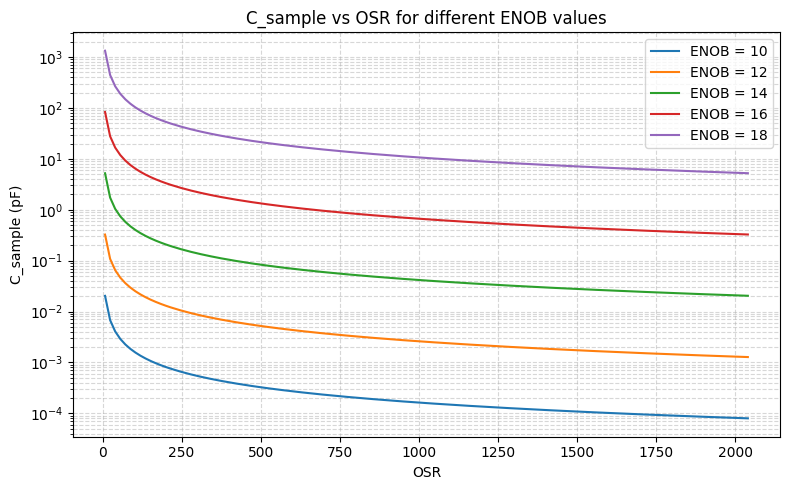

In [18]:
OSR_values = np.arange(8, 2048, 16)
enob_values = [10, 12, 14, 16, 18]

plt.figure(figsize=(8, 5))
for enob_plot in enob_values:
    SNR_plot = enob_plot * 6.02 + 1.76
    noise_limit_plot = FS / (2 * np.sqrt(2)) * 10**(-SNR_plot / 20)
    noise_cap_sample_plot = noise_limit_plot * np.sqrt(0.5)
    C_sample_plot = 4 * kt / (noise_cap_sample_plot**2 * OSR_values)
    plt.plot(OSR_values, C_sample_plot * 1e12, label=f"ENOB = {enob_plot}")

plt.xlabel("OSR")
plt.ylabel("C_sample (pF)")
plt.yscale("log")
plt.title("C_sample vs OSR for different ENOB values")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()


## Comment estimer si le bruit de l'INT1 est réaliste ?  
## -> Integrer le bruit plancher sur la bande passante, mais 

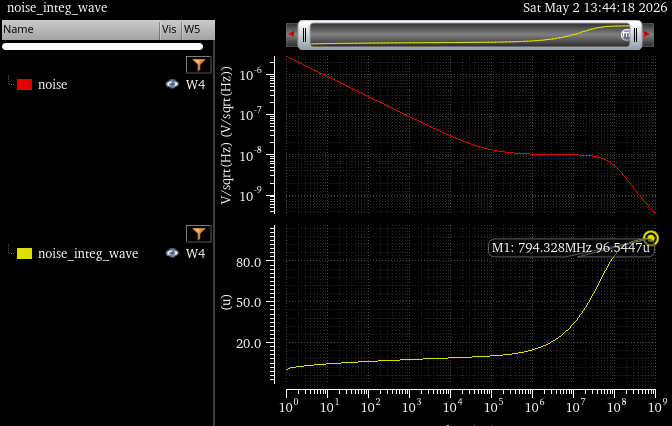
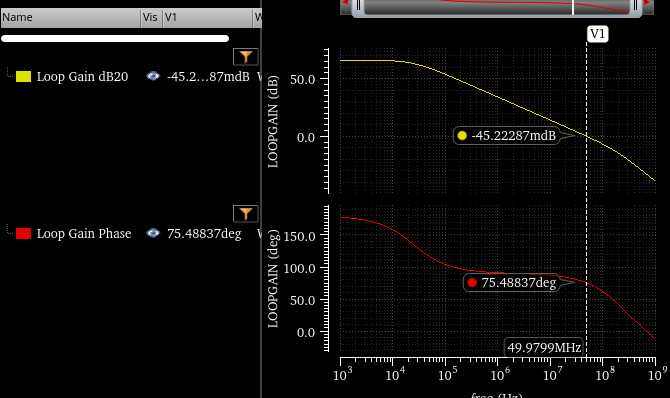

In [40]:
#Noise estimation for an Integrator 
plancher_noise = 10e-9 #V/sqrt(Hz)
fsample = 24e3
t_settle = 1/fsample * 0.5
print(f"t_settle: {t_settle * 1e6:.3f} us")


bw_close_loop = 1/t_settle #BW  close loop INT
print(f"bw_close_loop: {bw_close_loop * 1e-6:.3f} MHz")

noise_estimate = plancher_noise*np.sqrt(bw_close_loop)
print(f"noise_estimate: {noise_estimate * 1e6:.3f} µV_rms")


t_settle: 20.833 us
bw_close_loop: 0.048 MHz
noise_estimate: 2.191 µV_rms
